# Exercise project 3 - Cart Pole: basic DQN (Keras)

**Note:** I used generative AI (Claude) to assemble most of this notebook.
Reasoning: I have been having issues with getting myself to actually code most of these exercises as they didn't feel like they poke my brain in a way I enjoyed.

I have read all the code and adjusted where I didn't agree with it. The prompt was just asking it to work in a code style I can read the best and showed it some lecture notes and previous exercises I did myself to see how I usually work and what methods/modules we use.

At the end there is my own written analysis of the project. I tried to be a bit more detailed in it in exchange for skipping the ml coding.

In [2]:
import os
os.environ['KERAS_BACKEND'] = 'torch'

import random
from collections import deque

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

import keras
from keras.models import Sequential
from keras import layers

In [3]:
env = gym.make('CartPole-v1', max_episode_steps=500)

state_size = int(env.observation_space.shape[0])
action_size = int(env.action_space.n)

print('state size:', state_size)
print('action size:', action_size)
print('first observation:', env.reset()[0])

state size: 4
action size: 2
first observation: [-0.03249228  0.01705107  0.01406638  0.02585271]


In [4]:
gamma = 0.99
epsilon = 1.0
epsilon_min = 0.015
epsilon_decay = 0.9925

max_steps = 500
max_episodes = 500

learning_rate = 0.01
batch_size = 32
buffer_capacity = 1000

q_network_train_step_interval = 4
target_step_update_interval = 128

seed = 42
random.seed(seed)
np.random.seed(seed)
keras.utils.set_random_seed(seed)

In [5]:
def build_model():
    model = Sequential([
        layers.Input(shape=(state_size,)),
        layers.Dense(64, activation='relu'),
        layers.Dense(64, activation='relu'),
        layers.Dense(action_size, activation='linear'),   # raw Q-values, no activation
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate), loss='mse')
    return model


class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)

    def add(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)
        return (np.array(states, dtype=np.float32),
                np.array(actions),
                np.array(rewards, dtype=np.float32),
                np.array(next_states, dtype=np.float32),
                np.array(dones, dtype=np.float32))

    def __len__(self):
        return len(self.buffer)


q_network = build_model()
target_network = build_model()
target_network.set_weights(q_network.get_weights())

replay_buffer = ReplayBuffer(buffer_capacity)
q_network.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,610 (18.01 KB)

 Trainable params: 4,610 (18.01 KB)

 Non-trainable params: 0 (0.00 B)

## Training

In [ ]:
def to_array(tensor_or_array):
	return keras.ops.convert_to_numpy(tensor_or_array)


def choose_action(state, epsilon):
	if np.random.rand() < epsilon:
		return env.action_space.sample()
	q_values = to_array(q_network(state[None, :], training=False))
	return int(np.argmax(q_values[0]))


def train_step():
	states, actions, rewards, next_states, dones = replay_buffer.sample(batch_size)

	next_q = to_array(target_network(next_states, training=False))
	targets = to_array(q_network(states, training=False)).copy()

	best_next = np.max(next_q, axis=1)
	targets[np.arange(batch_size), actions] = rewards + gamma * best_next * (1.0 - dones)

	return q_network.train_on_batch(states, targets)

In [6]:
episode_rewards = []
episode_losses = []
total_steps = 0

for episode in range(max_episodes):
    state, _ = env.reset(seed=seed + episode)
    state = state.astype(np.float32)
    episode_reward = 0
    losses = []

    for step in range(max_steps):
        action = choose_action(state, epsilon)
        next_state, reward, terminated, truncated, _ = env.step(action)
        next_state = next_state.astype(np.float32)

        # only a real termination zeroes the future value, a time-limit cut-off does not
        replay_buffer.add(state, action, reward, next_state, float(terminated))

        state = next_state
        episode_reward += reward
        total_steps += 1

        if len(replay_buffer) >= batch_size and total_steps % q_network_train_step_interval == 0:
            losses.append(float(train_step()))

        if total_steps % target_step_update_interval == 0:
            target_network.set_weights(q_network.get_weights())

        if terminated or truncated:
            break

    epsilon = max(epsilon_min, epsilon * epsilon_decay)
    episode_rewards.append(episode_reward)
    episode_losses.append(np.mean(losses) if losses else np.nan)

    if (episode + 1) % 25 == 0:
        print(f'Episode {episode + 1}: reward {episode_reward:.0f}, '
              f'mean of last 25 = {np.mean(episode_rewards[-25:]):.1f}, epsilon = {epsilon:.3f}')

Episode 25: reward 17, mean of last 25 = 22.2, epsilon = 0.828
Episode 50: reward 21, mean of last 25 = 29.4, epsilon = 0.686
Episode 75: reward 34, mean of last 25 = 47.5, epsilon = 0.569
Episode 100: reward 43, mean of last 25 = 81.0, epsilon = 0.471
Episode 125: reward 57, mean of last 25 = 51.1, epsilon = 0.390
Episode 150: reward 63, mean of last 25 = 99.5, epsilon = 0.323
Episode 175: reward 114, mean of last 25 = 170.9, epsilon = 0.268
Episode 200: reward 48, mean of last 25 = 71.4, epsilon = 0.222
Episode 225: reward 159, mean of last 25 = 172.0, epsilon = 0.184
Episode 250: reward 282, mean of last 25 = 198.2, epsilon = 0.152
Episode 275: reward 422, mean of last 25 = 274.2, epsilon = 0.126
Episode 300: reward 500, mean of last 25 = 185.5, epsilon = 0.105
Episode 325: reward 500, mean of last 25 = 500.0, epsilon = 0.087
Episode 350: reward 10, mean of last 25 = 480.4, epsilon = 0.072
Episode 375: reward 10, mean of last 25 = 16.8, epsilon = 0.059
Episode 400: reward 500, mean 

## Training metrics

In [ ]:
def rolling(values, window, fn):
	values = np.array(values, dtype=float)
	return np.array([fn(values[max(0, i - window + 1): i + 1]) for i in range(len(values))])

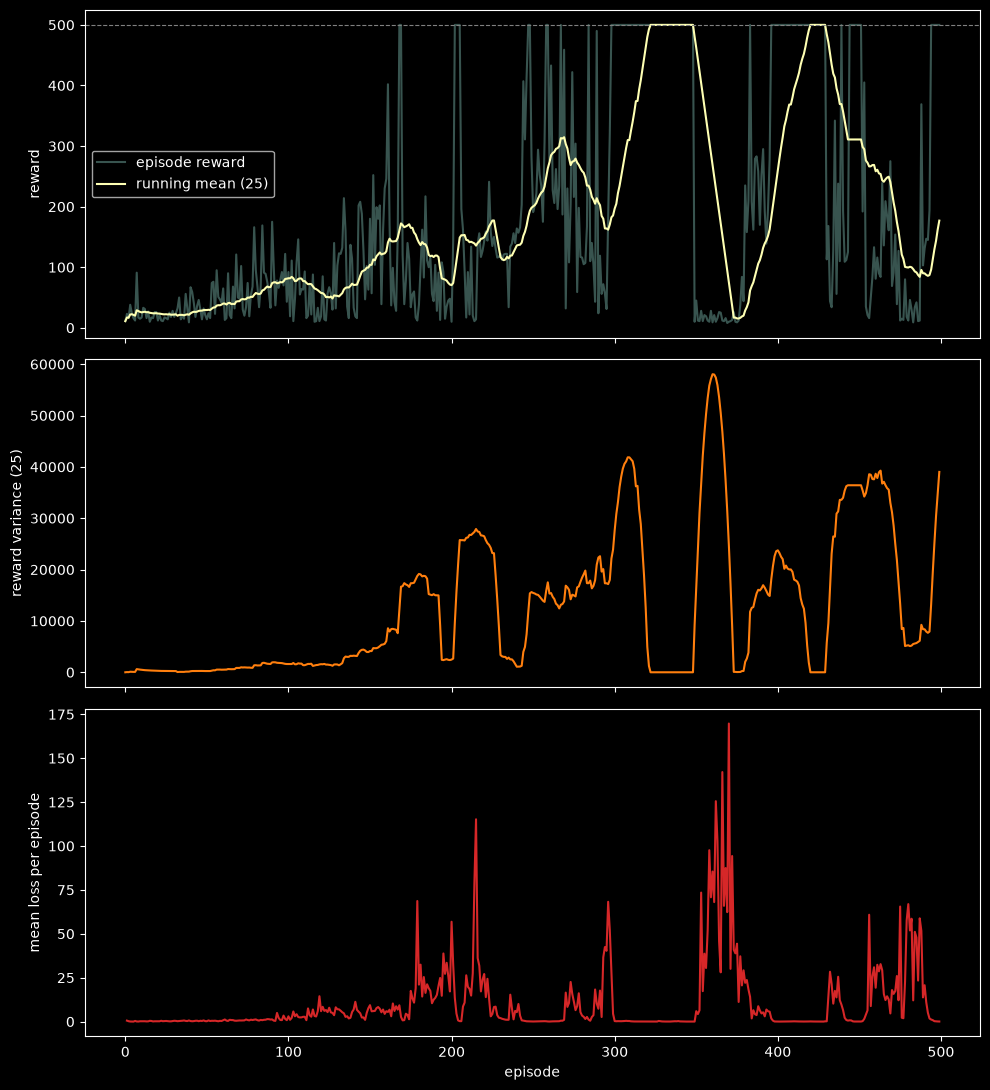

In [7]:
window = 25
rewards_arr = np.array(episode_rewards)

fig, axes = plt.subplots(3, 1, figsize=(10, 11), sharex=True)

axes[0].plot(rewards_arr, alpha=0.4, label='episode reward')
axes[0].plot(rolling(rewards_arr, window, np.mean), label=f'running mean ({window})')
axes[0].axhline(500, color='gray', linestyle='--', linewidth=0.8)
axes[0].set_ylabel('reward')
axes[0].legend()

axes[1].plot(rolling(rewards_arr, window, np.var), color='tab:orange')
axes[1].set_ylabel(f'reward variance ({window})')

axes[2].plot(episode_losses, color='tab:red')
axes[2].set_ylabel('mean loss per episode')
axes[2].set_xlabel('episode')

plt.tight_layout()
plt.show()

damn there was some bad collapse at 350ish, but it bounced back luckily

## Best-case runs

In [8]:
eval_env = gym.make('CartPole-v1', max_episode_steps=500)
eval_rewards = []

for i in range(20):
    state, _ = eval_env.reset(seed=1000 + i)
    done = False
    total = 0
    while not done:
        action = choose_action(state.astype(np.float32), epsilon=0.0)
        state, reward, terminated, truncated, _ = eval_env.step(action)
        total += reward
        done = terminated or truncated
    eval_rewards.append(total)

print('greedy rewards:', eval_rewards)
print('mean:', np.mean(eval_rewards))

greedy rewards: [500.0, 500.0, 500.0, 500.0, 500.0, 500.0, 500.0, 500.0, 500.0, 500.0, 500.0, 500.0, 500.0, 500.0, 500.0, 500.0, 500.0, 500.0, 500.0, 500.0]
mean: 500.0


## MY ANALYSIS
### How this differs from exercise projects 1 and 2
- The state space here was much smaller (just 6 states compared to the cut up bins/sections of the previous methods
- Instead of using a q-table we are using a deep learning network

### Replay buffer
A replay buffer is used to fix some issues with deep learning. The way it works is that it holds previous, older, runs and randomly uses it to teach the network, this helps to break down time correlations and makes sure the model doesn't forget things it learned in the past.

### Q-network vs target network
DQN has an issue of a moving target, chasing this causes instability and sometimes even an oscillating result. A target network solves this by making the moving target move much slower, allowing learning to keep up with it.

### Common neural networks vs DQN
They are similar in their building blocks, however differ in how their target is defined. ANNs have a fairly fix target while DQNs define their own with the before mentioned target network.

### DQN training vs classical Q-learning training
From what I see DQN training is much more chaotic/unstable